# FMI Model Exchange and Co-Simulation comparison

This notebook contains two related comparisons.

1. **Existing inverter:** native Simulink versus DPsim Model Exchange on the same balanced-load three-phase inverter case and 0.17 s load-step window. The checked DPsim run starts from the source configuration’s zero-voltage startup; it is not the separate consistent loaded-start initialization. The checked-in MathWorks FMU contains **Model Exchange only**, so it cannot be run through the Co-Simulation importer. The inverter comparison is therefore two-way.
2. **Dual-interface R-L test grid:** native Simulink, DPsim Model Exchange, DPsim Co-Simulation, and a fine-step DPsim Model Exchange reference, all using the same new FMI 3 FMU. This is the controlled three-way mode comparison.

The R-L FMU implements the continuous branch equations

\[
L\,\dot i_a=u_a-Ri_a,\qquad L\,\dot i_b=u_b-Ri_b,\qquad L\,\dot i_c=u_c-Ri_c
\]

with \(R=8\,\Omega\), \(L=20\,\mathrm{mH}\). Its test grid has a 2 Ω, 10 mH source impedance, a 100 Ω parallel load, and a balanced 0.75 pu voltage sag from 40 ms to 60 ms. All runs use a 10 ms voltage ramp from zero so the initial state is consistent. The DPsim ME and CS runs use the same 10 µs network step; the reference uses 2.5 µs.

Generated CSVs and timing manifests live below `build-fmi-cosim/`; this notebook keeps the comparison and plots reproducible without embedding large raw traces.

In [1]:
from pathlib import Path
import json, subprocess, sys, xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "dpsim-fmi/CMakeLists.txt").is_file()), None)
if REPO is None:
    raise RuntimeError("Start this notebook in the DPsim checkout or one of its subdirectories.")
BUILD = REPO / "build-fmi-cosim"
CASE = REPO / "dpsim-fmi/examples"
THREE_WAY = BUILD / "three-way"
DUAL = BUILD / "dual-interface-rl"
FMU = BUILD / "dual-interface-rl-fmu/ThreePhaseRL.fmu"
RUNNER = BUILD / "dpsim-fmi/FMI_EMT_Ph3_DualInterfaceRL"

print("Repository:", REPO)
print("Notebook output root:", DUAL)

Repository: /home/matthiasmees/dpsim-fmi-cosim
Notebook output root: /home/matthiasmees/dpsim-fmi-cosim/build-fmi-cosim/dual-interface-rl


## Reproduction and model capability check

The second test FMU is built from the checked-in FMI C implementation and FMI 3 model description. It is intentionally small and deterministic so one archive can exercise both import paths. The checked-in inverter FMU capability is inspected below before comparing it.

In [2]:
# Rebuild/rerun the dual-interface test only when outputs are missing.
expected = [
    DUAL / "native-simulink/native_reference.csv",
    DUAL / "me/logs/dual_interface_rl_me.csv",
    DUAL / "cs/logs/dual_interface_rl_cs.csv",
    DUAL / "me_fine/logs/dual_interface_rl_me.csv",
]
if not FMU.is_file():
    subprocess.run(["bash", str(CASE / "cosimulation/dual_interface_rl/build_fmu.sh")], check=True)
if not RUNNER.is_file():
    subprocess.run(["cmake", "-S", str(REPO), "-B", str(BUILD)], check=True)
    subprocess.run(["cmake", "--build", str(BUILD), "--target", "FMI_EMT_Ph3_DualInterfaceRL", "-j4"], check=True)
for folder, mode, step, downsample in [
    ("me", "me", 1e-5, 1), ("cs", "cs", 1e-5, 1), ("me_fine", "me", 2.5e-6, 1)
]:
    # Path composition without assuming that a previous run exists.
    csv = DUAL / folder / "logs" / f"dual_interface_rl_{mode}.csv"
    if not csv.is_file() and folder != "me_fine":
        run_dir = DUAL / folder
        run_dir.mkdir(parents=True, exist_ok=True)
        with (run_dir / "run.log").open("w") as log:
            subprocess.run([str(RUNNER), mode, str(FMU), "0.08", str(step), str(downsample)],
                           cwd=run_dir, stdout=log, stderr=subprocess.STDOUT, check=True)
    elif not csv.is_file():
        run_dir = DUAL / folder
        run_dir.mkdir(parents=True, exist_ok=True)
        with (run_dir / "run.log").open("w") as log:
            subprocess.run([str(RUNNER), mode, str(FMU), "0.08", str(step), str(downsample)],
                           cwd=run_dir, stdout=log, stderr=subprocess.STDOUT, check=True)
missing = [str(p) for p in expected if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing generated comparison data: " + ", ".join(missing) +
                            ". Build/run the Simulink reference with dual_interface_rl/matlab/run_native_reference.m.")

inverter_xml = CASE / "inverter/sources/modelDescription.xml"
root = ET.parse(inverter_xml).getroot()
print("Inverter FMU FMI version:", root.attrib.get("fmiVersion"))
print("Inverter interfaces:", [tag for tag in ("ModelExchange", "CoSimulation") if root.find(tag) is not None])
dual_root = ET.parse(BUILD / "dual-interface-rl-fmu/ThreePhaseRL.fmutmp/modelDescription.xml").getroot()
print("Dual R-L FMU interfaces:", [tag for tag in ("ModelExchange", "CoSimulation") if dual_root.find(tag) is not None])

Inverter FMU FMI version: 3.0
Inverter interfaces: ['ModelExchange']
Dual R-L FMU interfaces: ['ModelExchange', 'CoSimulation']


## Existing inverter: native Simulink and DPsim ME

The DPsim output is sampled every 100 µs and the native Simulink reference every 1 µs. Samples are paired at identical physical times; no trace shifting is applied. Current references use PCC KCL, including the native load and the switched load after 0.17 s. The load-step window is after startup; the whole-run table also exposes the initial-state mismatch and should not be presented as a loaded-start comparison.

In [3]:
inv_run = THREE_WAY / "dpsim-ssn"
inv_native = THREE_WAY / "native-simulink"
d = pd.read_csv(inv_run / "logs/fmi_mixed.csv", skipinitialspace=True)
r_full = pd.read_csv(inv_native / "native_simulink.csv")
t = d.time.to_numpy()
nearest = np.rint(t / 1e-6).astype(int)
if np.max(np.abs(r_full.time.to_numpy()[nearest] - t)) > 1e-10:
    raise AssertionError("Inverter traces do not share the same output timestamps.")
r = r_full.iloc[nearest].reset_index(drop=True)
step_on = t >= 0.17 - 1e-12
voltage_base = 25000 * np.sqrt(2/3)
current_base = 500000 / 25000 * np.sqrt(2/3)
inv_pairs = {}
for k, phase in enumerate("abc"):
    ref_v = r[f"v_pcc_{phase}"].to_numpy()
    ref_grid_i = r[f"i_grid_{phase}"].to_numpy()
    ref_converter_i = (ref_grid_i - ref_v/12500
                       - np.where(step_on, ref_v/25000, 0.0))
    inv_pairs[f"PCC voltage {phase}"] = (d[f"pcc_voltage_{k}"].to_numpy(), ref_v, voltage_base)
    inv_pairs[f"Grid current {phase}"] = (-d[f"line_current_{k}"].to_numpy(), ref_grid_i, current_base)
    inv_pairs[f"Converter current {phase}"] = (d[f"converter_current_{k}"].to_numpy(), ref_converter_i, current_base)

def summarize_pairs(pairs, time, mask, label):
    rows = []
    for name, (model, reference, base) in pairs.items():
        e = np.asarray(model)[mask] - np.asarray(reference)[mask]
        y = np.asarray(reference)[mask]
        rows.append({"window": label, "signal": name,
                     "max_abs_error": float(np.max(np.abs(e))),
                     "rms_error": float(np.sqrt(np.mean(e*e))),
                     "reference_rms": float(np.sqrt(np.mean(y*y))),
                     "RMS_error_%_base": float(100*np.sqrt(np.mean(e*e))/base)})
    return rows

inv_rows = []
for label, mask in [("whole run", np.ones(len(t), dtype=bool)),
                    ("load-step window 0.16–0.18 s", (t >= 0.16) & (t <= 0.18))]:
    inv_rows.extend(summarize_pairs(inv_pairs, t, mask, label))
inverter_metrics = pd.DataFrame(inv_rows)
inverter_metrics

,window,signal,max_abs_error,rms_error,reference_rms,RMS_error_%_base
0,whole run,PCC voltage a,0.682992,0.064793,14425.354161,0.000317
1,whole run,Grid current a,0.014626,0.002715,2.974194,0.016626
2,whole run,Converter current a,0.014638,0.002715,1.728527,0.016629
3,whole run,PCC voltage b,4822.019319,107.796703,14422.159238,0.528094
4,whole run,Grid current b,0.391643,0.009083,2.965891,0.055622
5,whole run,Converter current b,0.014594,0.002422,1.730318,0.014834
6,whole run,PCC voltage c,4822.019319,107.796703,14423.158942,0.528094
7,whole run,Grid current c,0.391643,0.009034,2.975881,0.055325
8,whole run,Converter current c,0.018835,0.002233,1.728123,0.013673
9,load-step window 0.16–0.18 s,PCC voltage a,0.489561,0.090612,15111.083506,0.000444


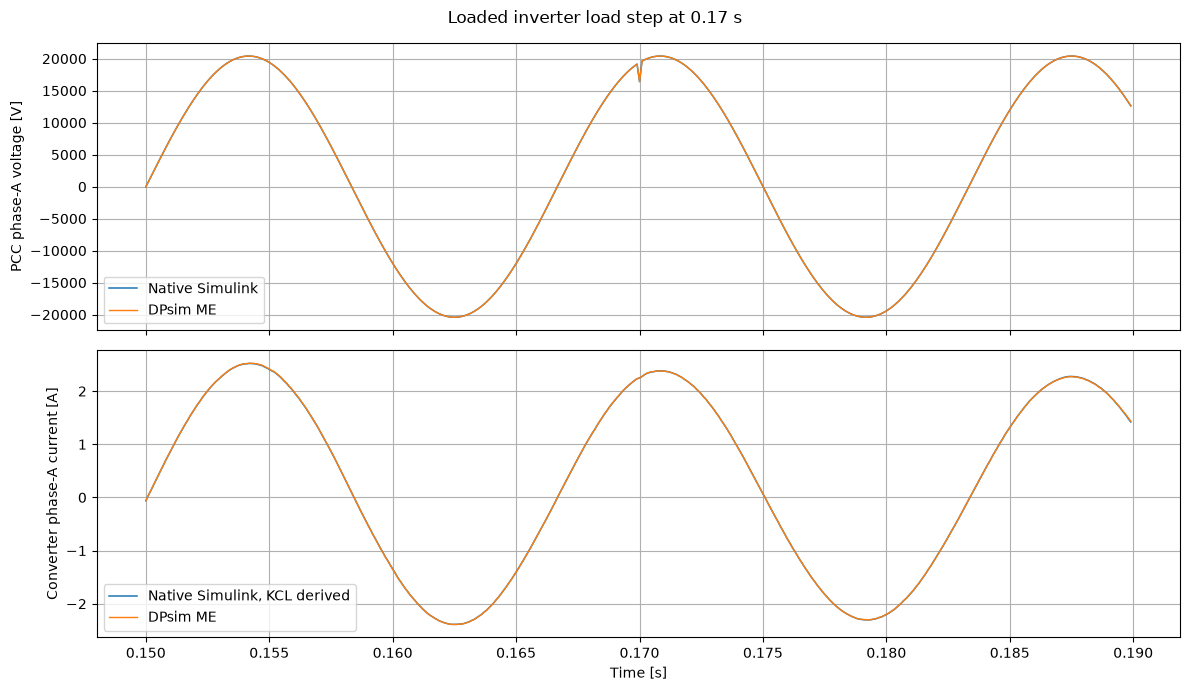

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
window = (t >= 0.15) & (t <= 0.19)
axes[0].plot(t[window], inv_pairs["PCC voltage a"][1][window], label="Native Simulink", lw=1.1)
axes[0].plot(t[window], inv_pairs["PCC voltage a"][0][window], label="DPsim ME", lw=1.0)
axes[0].set_ylabel("PCC phase-A voltage [V]")
axes[0].grid(True); axes[0].legend()
axes[1].plot(t[window], inv_pairs["Converter current a"][1][window], label="Native Simulink, KCL derived", lw=1.1)
axes[1].plot(t[window], inv_pairs["Converter current a"][0][window], label="DPsim ME", lw=1.0)
axes[1].set_ylabel("Converter phase-A current [A]")
axes[1].set_xlabel("Time [s]")
axes[1].grid(True); axes[1].legend()
fig.suptitle("Loaded inverter load step at 0.17 s")
fig.tight_layout()
PAPER_OUT = BUILD / "paper-comparison"
PAPER_OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(PAPER_OUT / "inverter_loadstep.png", dpi=160, bbox_inches="tight")
plt.show()

## Dual-interface R-L model: three-way mode comparison

The native Simulink reference is a continuous state-space realization of the same passive network and branch equations. It uses a fixed-step RK4 solver at 2.5 µs. DPsim ME and CS share the same FMU, parameters, source waveform, initial state, 10 µs communication/network step, and 10 µs logged output grid. The 2.5 µs DPsim ME run provides a second fine-step comparison.

In [5]:
native = pd.read_csv(DUAL / "native-simulink/native_reference.csv")
me = pd.read_csv(DUAL / "me/logs/dual_interface_rl_me.csv", skipinitialspace=True)
cs = pd.read_csv(DUAL / "cs/logs/dual_interface_rl_cs.csv", skipinitialspace=True)
me_fine = pd.read_csv(DUAL / "me_fine/logs/dual_interface_rl_me.csv", skipinitialspace=True)

# Align reference values at each run's actual timestamps. The sag boundaries are
# represented exactly in the native reference time base.
def native_reference_at(frame, group, phase):
    return np.interp(frame.time.to_numpy(), native.time.to_numpy(), native[f"{group}_{phase}"].to_numpy())

runs = {"DPsim ME 10 µs": me, "DPsim CS 10 µs": cs, "DPsim ME 2.5 µs": me_fine}
results = []
for run_name, frame in runs.items():
    frame_time = frame.time.to_numpy()
    windows = {
        "after ramp": frame_time >= 0.01,
        "sag": (frame_time >= 0.04) & (frame_time <= 0.06),
    }
    for window_name, mask in windows.items():
        for group, label, unit, base in [("pcc_v", "PCC voltage", "V", 325.27),
                                          ("fmu_i", "Branch current", "A", 20.0)]:
            errors, references = [], []
            for phase, letter in enumerate("abc"):
                y = native_reference_at(frame, group, letter)
                err = frame[f"{group}_{phase}"].to_numpy() - y
                errors.extend(err[mask]); references.extend(y[mask])
            errors = np.asarray(errors); references = np.asarray(references)
            results.append({"run": run_name, "window": window_name, "signal": label,
                            "max_abs_error_" + unit: float(np.max(np.abs(errors))),
                            "rms_error_" + unit: float(np.sqrt(np.mean(errors**2))),
                            "RMS_error_%_reference": float(100*np.sqrt(np.mean(errors**2))/np.sqrt(np.mean(references**2)))})
dual_metrics = pd.DataFrame(results)
dual_metrics

,run,window,signal,max_abs_error_V,rms_error_V,RMS_error_%_reference,max_abs_error_A,rms_error_A
0,DPsim ME 10 µs,after ramp,PCC voltage,2.403279,0.065920,0.042072,NaN,NaN
1,DPsim ME 10 µs,after ramp,Branch current,NaN,NaN,0.009390,0.007931,1.445403e-03
2,DPsim ME 10 µs,sag,PCC voltage,2.403279,0.097602,0.077577,NaN,NaN
3,DPsim ME 10 µs,sag,Branch current,NaN,NaN,0.015042,0.007931,1.914990e-03
4,DPsim CS 10 µs,after ramp,PCC voltage,2.540142,0.105024,0.067029,NaN,NaN
5,DPsim CS 10 µs,after ramp,Branch current,NaN,NaN,0.115780,0.027464,1.782182e-02
6,DPsim CS 10 µs,sag,PCC voltage,2.540142,0.129696,0.103087,NaN,NaN
7,DPsim CS 10 µs,sag,Branch current,NaN,NaN,0.117327,0.026653,1.493672e-02
8,DPsim ME 2.5 µs,after ramp,PCC voltage,0.005378,0.000099,0.000063,NaN,NaN
9,DPsim ME 2.5 µs,after ramp,Branch current,NaN,NaN,0.000005,0.000018,7.262367e-07


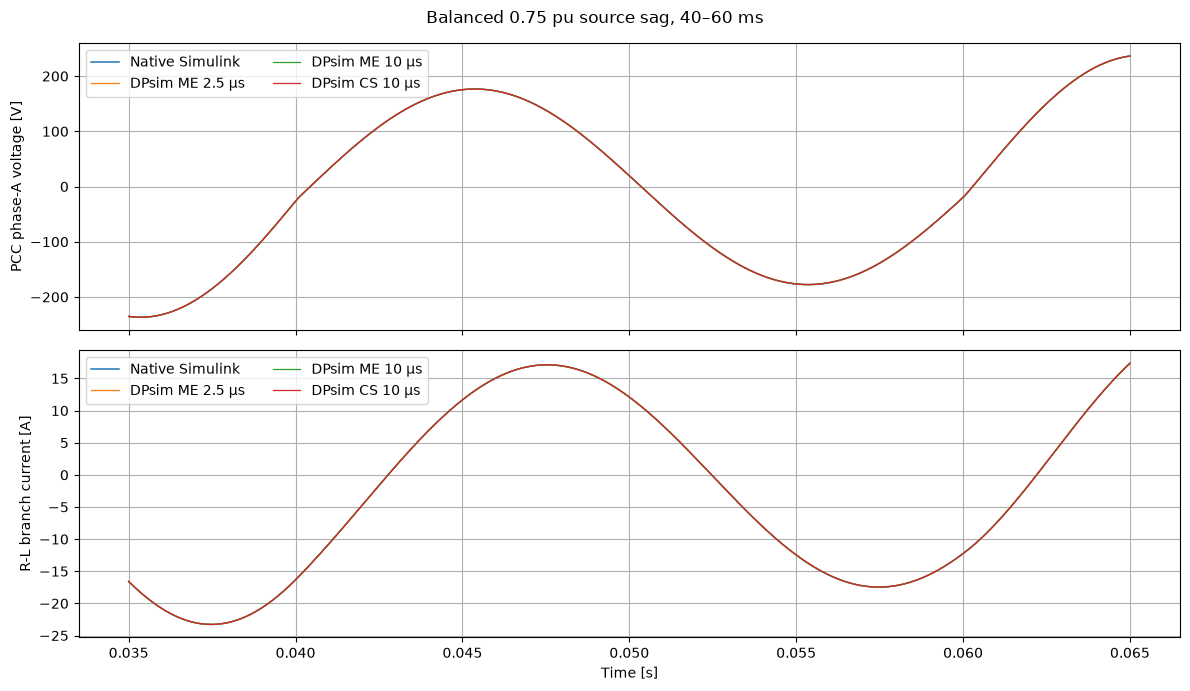

In [6]:
# A sag-centered overlay: phase-A voltage and branch current, plus phase currents.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
win_n = (native.time >= 0.035) & (native.time <= 0.065)
win_c = (cs.time >= 0.035) & (cs.time <= 0.065)
axes[0].plot(native.time[win_n], native.pcc_v_a[win_n], label="Native Simulink", lw=1.1)
axes[0].plot(me_fine.time[win_n], me_fine.pcc_v_0[win_n], label="DPsim ME 2.5 µs", lw=0.9)
axes[0].plot(me.time[(me.time >= .035)&(me.time <= .065)], me.pcc_v_0[(me.time >= .035)&(me.time <= .065)], label="DPsim ME 10 µs", lw=0.9)
axes[0].plot(cs.time[win_c], cs.pcc_v_0[win_c], label="DPsim CS 10 µs", lw=0.9)
axes[0].set_ylabel("PCC phase-A voltage [V]"); axes[0].grid(True); axes[0].legend(ncol=2)
axes[1].plot(native.time[win_n], native.fmu_i_a[win_n], label="Native Simulink", lw=1.1)
axes[1].plot(me_fine.time[win_n], me_fine.fmu_i_0[win_n], label="DPsim ME 2.5 µs", lw=0.9)
axes[1].plot(me.time[(me.time >= .035)&(me.time <= .065)], me.fmu_i_0[(me.time >= .035)&(me.time <= .065)], label="DPsim ME 10 µs", lw=0.9)
axes[1].plot(cs.time[win_c], cs.fmu_i_0[win_c], label="DPsim CS 10 µs", lw=0.9)
axes[1].set_ylabel("R-L branch current [A]"); axes[1].set_xlabel("Time [s]"); axes[1].grid(True); axes[1].legend(ncol=2)
fig.suptitle("Balanced 0.75 pu source sag, 40–60 ms")
fig.tight_layout()
PAPER_OUT = BUILD / "paper-comparison"
PAPER_OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(PAPER_OUT / "dual_rl_sag_overlay.png", dpi=160, bbox_inches="tight")
plt.show()

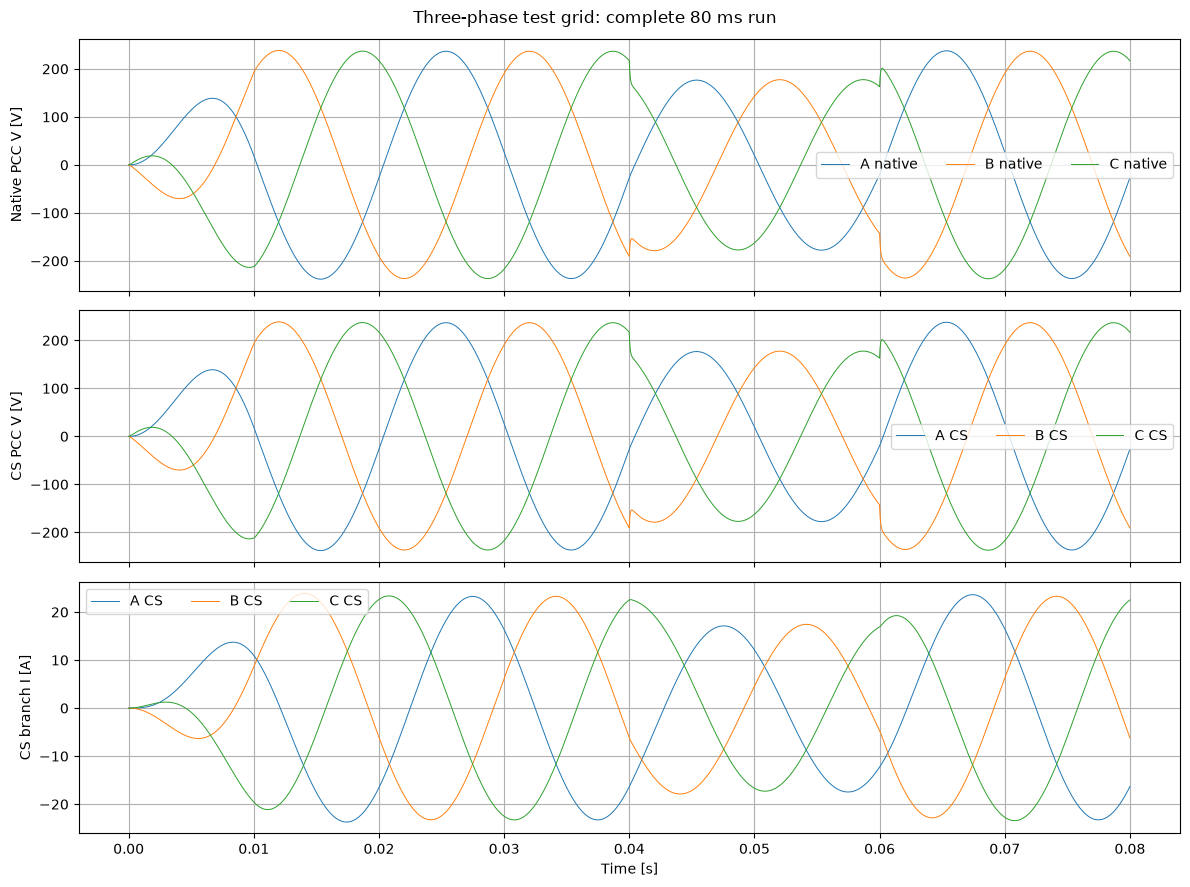

ME diagnostics: {'max_newton_iterations': 1, 'mean_newton_iterations_after_initial_point': 1.0, 'max_scaled_newton_residual': 0.00033}
CS diagnostics: {'completed_doStep_calls': 8000, 'communication_step_s': 1e-05, 'coupling': 'explicit: last accepted FMU current is held during each network solve'}
Saved compact comparison artifacts to /home/matthiasmees/dpsim-fmi-cosim/build-fmi-cosim/paper-comparison


In [7]:
# All-phase waveform overview and convergence/timing diagnostics.
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for phase, letter in enumerate("abc"):
    axes[0].plot(native.time, native[f"pcc_v_{letter}"], label=f"{letter.upper()} native", lw=.7)
    axes[1].plot(cs.time, cs[f"pcc_v_{phase}"], label=f"{letter.upper()} CS", lw=.7)
    axes[2].plot(cs.time, cs[f"fmu_i_{phase}"], label=f"{letter.upper()} CS", lw=.7)
axes[0].set_ylabel("Native PCC V [V]"); axes[1].set_ylabel("CS PCC V [V]"); axes[2].set_ylabel("CS branch I [A]")
for ax in axes: ax.grid(True); ax.legend(ncol=3)
axes[-1].set_xlabel("Time [s]")
fig.suptitle("Three-phase test grid: complete 80 ms run")
fig.tight_layout()
PAPER_OUT = BUILD / "paper-comparison"
PAPER_OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(PAPER_OUT / "dual_rl_all_phases.png", dpi=160, bbox_inches="tight")
plt.show()

me_diag = {
    "max_newton_iterations": int(me.newton_iterations.max()),
    "mean_newton_iterations_after_initial_point": float(me.newton_iterations.iloc[1:].mean()),
    "max_scaled_newton_residual": float(me.newton_residual.max()),
}
cs_diag = {"completed_doStep_calls": int(cs.fmi_do_steps.iloc[-1]),
           "communication_step_s": 1e-5,
           "coupling": "explicit: last accepted FMU current is held during each network solve"}

def read_wall(folder):
    return (DUAL / folder / "time.txt").read_text().strip()

timings = pd.DataFrame([
    {"simulation": "Native Simulink state-space", "step_s": 2.5e-6,
     "samples": len(native), "measured_time": json.loads((DUAL / "native-simulink/timing.json").read_text())["simulation_wall_s"],
     "time_scope": "Simulink simulation only"},
    {"simulation": "DPsim ME", "step_s": 1e-5, "samples": len(me),
     "measured_time": float(read_wall("me").split("wall_s=")[1].split()[0]), "time_scope": "process wall time"},
    {"simulation": "DPsim CS", "step_s": 1e-5, "samples": len(cs),
     "measured_time": float(read_wall("cs").split("wall_s=")[1].split()[0]), "time_scope": "process wall time"},
    {"simulation": "DPsim ME fine reference", "step_s": 2.5e-6, "samples": len(me_fine),
     "measured_time": float(read_wall("me_fine").split("wall_s=")[1].split()[0]), "time_scope": "process wall time"},
])
print("ME diagnostics:", me_diag)
print("CS diagnostics:", cs_diag)
timings

# Keep compact final metrics and timing manifests next to the generated traces.
PAPER_OUT = BUILD / "paper-comparison"
PAPER_OUT.mkdir(parents=True, exist_ok=True)
inverter_metrics.to_csv(PAPER_OUT / "inverter_native_vs_me_metrics.csv", index=False)
dual_metrics.to_csv(PAPER_OUT / "dual_interface_rl_metrics.csv", index=False)
summary = {
    "inverter_fmu_interfaces": [tag for tag in ("ModelExchange", "CoSimulation") if root.find(tag) is not None],
    "inverter_timing_scope_note": "DPsim and MATLAB measurements overlap in time; do not use as a speed ratio.",
    "dual_interface_rl_me_diagnostics": me_diag,
    "dual_interface_rl_cs_diagnostics": cs_diag,
    "dual_interface_rl_timings": timings.to_dict(orient="records"),
    "dual_interface_rl_grid": {"source_R_ohm": 2.0, "source_L_H": 0.01, "load_R_ohm": 100.0, "branch_R_ohm": 8.0, "branch_L_H": 0.02, "sag_start_s": 0.04, "sag_end_s": 0.06, "sag_factor": 0.75},
}
(PAPER_OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print("Saved compact comparison artifacts to", PAPER_OUT)

## Reading the results

- The inverter case is a valid native-Simulink versus DPsim-ME comparison at matching output times. The inverter archive has no `<CoSimulation>` interface, so it cannot provide a same-model third result. Exporting or rebuilding the MathWorks inverter FMU with CS support requires its source model and a compatible exporter; relabeling the existing archive would be invalid.
- The second test is a genuine three-way comparison on the same electrical branch model. The fine DPsim ME run tracks the native Simulink state-space reference closely. The coarse DPsim ME run shows the fixed-step network discretization error. The CS run adds the expected explicit current-hold error; it is small in this linear R-L case and is quantified above, but the component does not claim implicit Newton convergence.
- Timings use different scopes: Simulink simulation-only time versus DPsim process wall time. The earlier inverter timing pair ran concurrently on an unoptimized build, so those numbers are reported only as measurements and must not be treated as a fair speed ratio. The R-L comparison timings are collected from sequential runs on this machine; they are still environment-specific.

The notebook does not substitute the R-L test model for inverter results. It documents exactly where the existing inverter FMU interface prevents an apples-to-apples Co-Simulation run.